# Exploratory data analysis: SF 311 requests and census tract income

CP101 Fall 2026 · Track B midterm

This notebook shows what our data looks like at each step of the pipeline in `src/`, the problems we found,
and why we clean the data the way we do. It does not change any data: it only reads the files that
`python -m src.main` makes.

**Run it after** `python -m src.main` (it needs `data/raw/`, `data/processed/` and `logs/`).
Use the project's `.venv` as the kernel.

1. Raw 311 data
2. Cleaning: how many rows each rule removed
3. Cleaned 311 data
4. Census (ACS) data
5. Spatial join check
6. Analysis: requests per resident by income group

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# let the notebook import our code in src/ (the notebook runs from the notebooks/ folder)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.analysis import compute_metrics
from src.data import load_data
from src.utils import config

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Raw 311 data

Source: DataSF **311 Cases** (`vw6y-z8j6`), every request opened 2020–2025.
One row = one request. The download saves one file per month in `data/raw/sf311/`.

### 1.1 How many requests per month
The download log (`_manifest.csv`) records how many rows each month had; each month was checked against the API's own count.

In [2]:
manifest = pd.read_csv(config.SF311_RAW / "_manifest.csv")
print("months:", len(manifest), "| total raw requests:", f"{manifest['rows'].sum():,}")
print("every month matches the API count:", (manifest["rows"] == manifest["expected_rows"]).all())
manifest.head()

months: 72 | total raw requests: 4,374,679
every month matches the API count: True


,month,rows,expected_rows,downloaded_at_utc
0,2020-01,62668,62668,2026-11-01T22:35:26Z
1,2020-02,59445,59445,2026-11-01T22:35:41Z
2,2020-03,48991,48991,2026-11-01T22:35:46Z
3,2020-04,39766,39766,2026-11-01T22:35:54Z
4,2020-05,45471,45471,2026-11-01T22:36:01Z


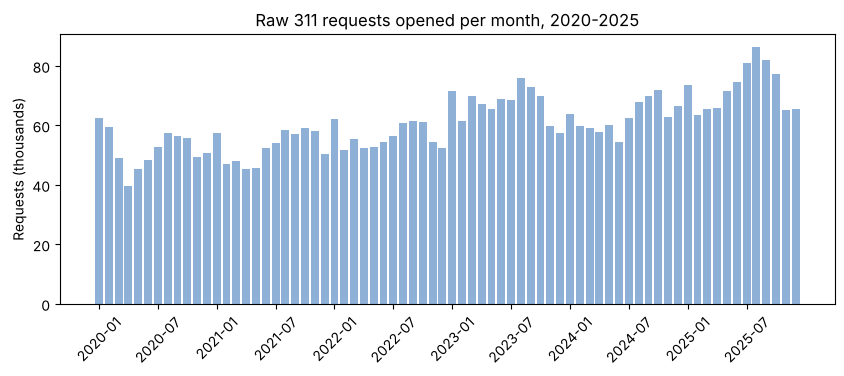

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(manifest["month"], manifest["rows"] / 1000, color="#8fb0d6")
ax.set_xticks(manifest["month"][::6])
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Requests (thousands)")
ax.set_title("Raw 311 requests opened per month, 2020-2025")
plt.show()

### 1.2 One year of raw data (2024)
The full raw data has 4.4 million rows, so here we look at one year. 2024 is the year the categories were renamed (see 1.4).

In [4]:
raw = load_data.load_raw_311(2024)
raw.shape

(756525, 15)

In [5]:
raw.head()

,service_request_id,requested_datetime,closed_date,updated_datetime,status_description,status_notes,agency_responsible,service_name,service_subtype,service_details,source,supervisor_district,analysis_neighborhood,lat,long
0,17709947,2024-01-01T10:01:00.000,2024-03-02T11:48:26.000,2024-03-02T11:48:26.000,Closed,Case Resolved - no graffiti found,DPW Ops Queue,Graffiti,Graffiti on Building_commercial,Building_commercial - Not_Offensive,Web,6.00000,South of Market,37.770958000000,-122.405014000000
1,17714265,2024-01-02T17:01:00.000,2024-03-22T13:19:20.000,2024-03-22T13:19:20.000,Closed,Case Resolved,DPW Ops Queue,Graffiti,Graffiti on Building_commercial,Building_commercial - Not_Offensive,Mobile/Open311,6.00000,South of Market,37.780178333333,-122.408766666667
2,17715109,2024-01-01T04:01:00.000,2024-01-09T08:50:00.000,2024-01-09T08:50:00.000,Closed,Case Resolved,DPW Ops Queue,Street and Sidewalk Cleaning,General Cleaning,Other Loose Garbage,Phone,5.00000,Tenderloin,37.785122670000,-122.412675580000
3,17715154,2024-01-01T06:03:00.000,2024-01-06T08:00:00.000,2024-01-06T08:00:00.000,Closed,Case Resolved,DPW Ops Queue,Street and Sidewalk Cleaning,Human or Animal Waste,Human or Animal Waste,Phone,5.00000,Tenderloin,37.784090950000,-122.417525240000
4,17715224,2024-01-01T08:01:00.000,2024-01-18T07:16:00.000,2024-01-18T07:16:00.000,Closed,Case Resolved,DPW Ops Queue,Street and Sidewalk Cleaning,General Cleaning,Other Loose Garbage,Web,5.00000,Tenderloin,37.785622000000,-122.415726000000


Every column is saved as **text**, exactly as the API sends it. Turning dates and coordinates into
real dates and numbers is the cleaning step's job (`clean_year()` in `src/data/process_data.py`).

In [6]:
raw.dtypes

service_request_id       str
requested_datetime       str
closed_date              str
updated_datetime         str
status_description       str
status_notes             str
agency_responsible       str
service_name             str
service_subtype          str
service_details          str
source                   str
supervisor_district      str
analysis_neighborhood    str
lat                      str
long                     str
dtype: object

### 1.3 Missing values
`lat`/`long` are missing for some requests, so those cannot be placed in a census tract. `closed_date` is missing for requests that were still open when we downloaded.

In [7]:
missing = raw.isna().sum().to_frame("missing")
missing["pct"] = (100 * missing["missing"] / len(raw)).round(2)
missing

,missing,pct
service_request_id,0,0.00
requested_datetime,0,0.00
closed_date,28702,3.79
updated_datetime,0,0.00
status_description,0,0.00
status_notes,11779,1.56
agency_responsible,0,0.00
service_name,0,0.00
service_subtype,10284,1.36
service_details,132063,17.46


### 1.4 Problem: categories were renamed in June 2024
The same kind of problem has different `service_name` values before and after June 2024
(for example `Graffiti` → `Graffiti Public` / `Graffiti Private`, `Encampments` → `Encampment`,
and abandoned vehicles moved under `Parking Enforcement`). If we counted `service_name` directly,
these types would look like they disappeared in 2024. Our `data/reference/category_map.csv` maps the old
and new names to one `request_type`.

In [8]:
raw["half"] = raw["requested_datetime"].str[5:7].astype(int).map(lambda m: "Jan-Jun" if m <= 6 else "Jul-Dec")
names = ["Graffiti", "Graffiti Public", "Graffiti Private", "Encampments", "Encampment",
         "Abandoned Vehicle", "Parking Enforcement"]
pd.crosstab(raw.loc[raw["service_name"].isin(names), "service_name"], raw["half"])

half,Jan-Jun,Jul-Dec
service_name,,
Abandoned Vehicle,8556,0
Encampment,2068,27595
Encampments,17839,0
Graffiti,35967,0
Graffiti Private,735,7736
Graffiti Public,3226,31120
Parking Enforcement,52789,66941


In [9]:
category_map, status_rules = load_data.load_reference()
print(len(category_map), "rows in category_map.csv;",
      category_map.loc[category_map["in_scope"], "request_type"].nunique(), "request types we study")
category_map[["service_name", "service_subtype", "request_type", "in_scope"]].head(10)

171 rows in category_map.csv; 10 request types we study


,service_name,service_subtype,request_type,in_scope
0,Abandoned Vehicle,*,Abandoned Vehicle,True
1,Parking Enforcement,abandoned_vehicle,Abandoned Vehicle,True
2,Parking Enforcement,abandoned_vehicle_callback,Abandoned Vehicle,True
3,Encampment,*,Encampments,True
4,Encampments,*,Encampments,True
5,Graffiti,*,Graffiti,True
6,Graffiti Private,*,Graffiti,True
7,Graffiti Public,*,Graffiti,True
8,Illegal Postings,*,Illegal Postings,True
9,Catch Basin Maintenance,*,Sewer,True


### 1.5 Where requests come from
`source` is how the request was made. `Test` records are not real requests, and the rename of
`Mobile/Open311` → `Mobile` is another 2024 change.

In [10]:
raw["source"].value_counts(dropna=False)

source
Mobile               312153
Mobile/Open311       221350
Phone                136378
Web                   70810
Integrated Agency     10323
NaN                    4032
Twitter                1180
In Person               205
Test                     54
Email                    40
Name: count, dtype: int64

### 1.6 Problem: some requests are closed without real service
The closure note (`status_notes`) shows that many requests were closed as a duplicate of another request,
transferred to another agency, or closed for administrative reasons. They are not real service, so we
label them with the patterns in `data/reference/status_rules.csv`.

In [11]:
status_rules[["reason", "pattern", "example"]]

,reason,pattern,example
0,duplicate,duplicat,case is a duplicate - this issue has already b...
1,transferred,\btransferr?ed\b|\btransfer\b,transferred - your request falls under the res...
2,transferred,\breferred to\b,case transferred - area was cleaned around the...
3,administrative,administrativ,administrative closure - closed for administra...
4,administrative,per process,case resolved - per process - cases are closed...
5,administrative,closed: no response|^no response,case resolved - closed: no response from dpw b...
6,administrative,suspended public works enforcement|will be dis...,case resolved - as part of the unprecedented c...
7,not_actionable,case is invalid|^invalid\b,case is invalid - requests related to the conc...
8,not_actionable,insufficient info|incomplete info|required inf...,insufficient information provided
9,not_actionable,cancel,cancelled - planned maintenance


## 2. Cleaning: how many rows each rule removed

`clean_requests()` applies the rules in this order. A removed request is counted under the **first** rule it breaks.
These tables are written by the pipeline to `logs/`.

In [12]:
cleaning_log = pd.read_csv(config.LOGS / "cleaning_log.csv")
cleaning_log

,rule,description,removed,remaining,pct_of_raw_removed
0,raw_rows,Requests in the raw download,0,4374679,0.00
1,repeated_id,The same service_request_id appears again (fir...,0,4374679,0.00
2,test_record,Test records (source = 'Test'),546,4374133,0.01
3,out_of_scope_type,Not one of the in-scope request types (categor...,1269348,3104785,29.02
4,closed_duplicate,Closure note says: duplicate (status_rules.csv),280297,2824488,6.41
5,closed_transferred,Closure note says: transferred (status_rules.csv),85131,2739357,1.95
6,closed_administrative,Closure note says: administrative (status_rule...,118334,2621023,2.70
7,closed_not_actionable,Closure note says: not actionable (status_rule...,58777,2562246,1.34
8,bad_dates,"Closed before it was opened, after the downloa...",1682,2560564,0.04
9,missing_location,"No coordinates, or the (0, 0) placeholder",125627,2434937,2.87


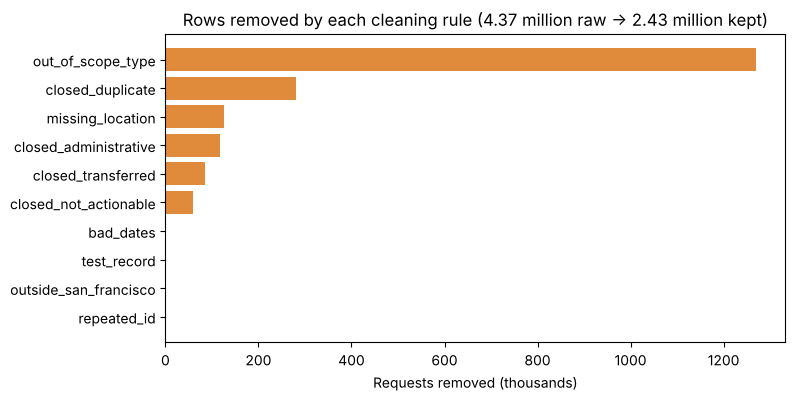

In [13]:
removed = cleaning_log.iloc[1:].sort_values("removed")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(removed["rule"], removed["removed"] / 1000, color="#e08a3c")
ax.set_xlabel("Requests removed (thousands)")
ax.set_title("Rows removed by each cleaning rule (4.37 million raw -> 2.43 million kept)")
plt.show()

### 2.1 By year
Between 51% and 59% of requests are kept each year. 2022 and 2023 keep the least because many requests in those years have no coordinates (`missing_location`).

In [14]:
pd.read_csv(config.LOGS / "cleaning_log_by_year.csv", index_col=0)

,raw,repeated_id,test_record,out_of_scope_type,closed_duplicate,closed_transferred,closed_administrative,closed_not_actionable,bad_dates,missing_location,outside_san_francisco,kept,pct_kept
year,,,,,,,,,,,,,
2020,627380,0,0,181458,37897,15259,17725,7325,40,406,1,367269,58.5
2021,633508,0,0,186827,48355,14392,15324,5998,41,936,1,361634,57.1
2022,675997,0,0,203312,46582,15690,20186,7297,46,40031,0,342853,50.7
2023,808842,0,0,210670,54303,10666,39354,7258,63,55051,0,431477,53.3
2024,756525,0,54,215658,38814,11689,15601,11737,989,24424,4,437555,57.8
2025,872427,0,492,271423,54346,17435,10144,19162,503,4779,3,494140,56.6


### 2.2 By channel
**Problem:** phone requests lose many more rows to `missing_location` than other channels (in 2022 and 2023 a lot of
phone requests have no coordinates). So phone requests are under-represented in our cleaned data.

In [15]:
by_channel = pd.read_csv(config.LOGS / "cleaning_log_by_channel.csv", index_col=0)
by_channel[["raw", "missing_location", "kept", "pct_kept"]]

,raw,missing_location,kept,pct_kept
channel,,,,
Integrated Agency,54421,16383,19596,36.0
Mobile,2821244,3088,1817138,64.4
Other,23974,1465,9156,38.2
Phone,865893,102609,300096,34.7
Web,609147,2082,288942,47.4


### 2.3 By request type
Out-of-scope types are everything we do not study (for example parking or noise).

In [16]:
pd.read_csv(config.LOGS / "cleaning_log_by_type.csv", index_col=0)[["raw", "kept", "pct_kept"]]

,raw,kept,pct_kept
request_type,,,
(out-of-scope types),1269670,0,0.0
Abandoned Vehicle,95001,73406,77.3
Encampments,233722,166371,71.2
Graffiti,494689,281327,56.9
Illegal Postings,72942,47568,65.2
Sewer,68250,45529,66.7
Sidewalk and Curb,62657,39192,62.6
Street Defects,40298,26623,66.1
Street and Sidewalk Cleaning,1933456,1693861,87.6


## 3. Cleaned 311 data

`data/processed/requests_with_tracts.parquet` is the cleaned data plus the census tract each request falls in (from step 3 of the pipeline).

In [17]:
requests = pd.read_parquet(config.REQUESTS_WITH_TRACTS)
requests.shape

(2434928, 23)

In [18]:
requests.head()

,service_request_id,request_type,opened,closed,year,is_open,days_to_close,days_open_at_snapshot,closed_date_only,channel,lat,lon,closure_note_category,service_name,service_subtype,service_details,source,agency_responsible,status_notes,supervisor_district,analysis_neighborhood,GEOID,spatial_join_status
0,11884029,Street and Sidewalk Cleaning,2020-01-01 00:07:45,2020-01-01 09:44:49,2020,False,0.400741,NaN,False,Integrated Agency,37.764374,-122.430885,None,Street and Sidewalk Cleaning,Bulky Items,Refrigerator,Integrated Agency,Recology_Abandoned,Case Resolved - Pickup completed.,8.00000,Castro/Upper Market,06075020300,within
1,11884088,Street and Sidewalk Cleaning,2020-01-01 00:56:00,2020-01-08 08:26:00,2020,False,7.312500,NaN,False,Phone,37.749508,-122.494255,None,Street and Sidewalk Cleaning,General Cleaning,Other Loose Garbage,Phone,DPW Ops Queue,Case Resolved - not thing found,4.00000,Sunset/Parkside,06075032901,within
2,11884116,Street and Sidewalk Cleaning,2020-01-01 01:07:00,2020-01-02 00:33:00,2020,False,0.976389,NaN,False,Phone,37.795876,-122.400482,None,Street and Sidewalk Cleaning,Hazardous Materials,Glass,Phone,DPW Ops Queue,Case Resolved,3.00000,Financial District/South Beach,06075010500,within
3,11884133,Street and Sidewalk Cleaning,2020-01-01 01:25:00,2020-01-02 00:12:00,2020,False,0.949306,NaN,False,Phone,37.802513,-122.444466,None,Street and Sidewalk Cleaning,Hazardous Materials,Glass,Phone,DPW Ops Queue,Case Resolved,2.00000,Marina,06075012700,within
4,11884210,Street and Sidewalk Cleaning,2020-01-01 02:33:00,2020-01-07 23:18:00,2020,False,6.864583,NaN,False,Mobile,37.771418,-122.428651,None,Street and Sidewalk Cleaning,General Cleaning,Other Loose Garbage,Mobile/Open311,DPW Ops Queue,Case Resolved,5.00000,Hayes Valley,06075016801,within


In [19]:
requests.dtypes

service_request_id                  str
request_type                        str
opened                   datetime64[us]
closed                   datetime64[us]
year                              int32
is_open                            bool
days_to_close                   float64
days_open_at_snapshot           float64
closed_date_only                   bool
channel                             str
lat                             float64
lon                             float64
closure_note_category            object
service_name                        str
service_subtype                     str
service_details                     str
source                              str
agency_responsible                  str
status_notes                        str
supervisor_district                 str
analysis_neighborhood               str
GEOID                            string
spatial_join_status                 str
dtype: object

### 3.1 Requests per type
**Street and Sidewalk Cleaning** is about 70% of all requests, far more than any other type. That is why
chart 2 uses a log scale and why we also look at each type separately.

In [20]:
type_counts = requests["request_type"].value_counts().to_frame("requests")
type_counts["pct"] = (100 * type_counts["requests"] / len(requests)).round(1)
type_counts

,requests,pct
request_type,,
Street and Sidewalk Cleaning,1693861,69.6
Graffiti,281327,11.6
Encampments,166371,6.8
Abandoned Vehicle,73406,3.0
Tree Maintenance,48628,2.0
Illegal Postings,47568,2.0
Sewer,45529,1.9
Sidewalk and Curb,39192,1.6
Street Defects,26623,1.1


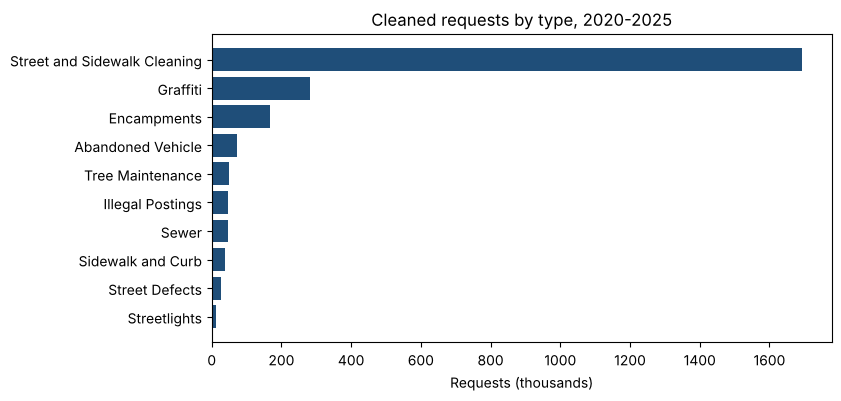

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(type_counts.index[::-1], type_counts["requests"][::-1] / 1000, color="#1f4e79")
ax.set_xlabel("Requests (thousands)")
ax.set_title("Cleaned requests by type, 2020-2025")
plt.show()

### 3.2 Requests per year

In [22]:
requests["year"].value_counts().sort_index().to_frame("requests")

,requests
year,
2020,367269
2021,361634
2022,342853
2023,431477
2024,437555
2025,494140


### 3.3 Channel by year
Mobile app requests grow over time; this matters for the final (response time can depend on channel).

In [23]:
pd.crosstab(requests["year"], requests["channel"])

channel,Integrated Agency,Mobile,Other,Phone,Web
year,,,,,
2020,9227,240242,1530,78649,37621
2021,5164,240755,863,71815,43037
2022,1934,262562,524,33733,44100
2023,2374,369665,204,16834,42400
2024,824,365817,2474,41585,26855
2025,73,338097,3561,57480,94929


### 3.4 Coordinates are inside San Francisco
After cleaning, every request has coordinates inside the San Francisco bounding box
(`MIN_LAT`..`MAX_LAT`, `MIN_LON`..`MAX_LON` in `src/utils/config.py`).

In [24]:
requests[["lat", "lon"]].describe().round(4)

,lat,lon
count,2.434928e+06,2.434928e+06
mean,3.776570e+01,-1.224295e+02
std,2.280000e-02,2.730000e-02
min,3.770700e+01,-1.225144e+02
25%,3.775230e+01,-1.224424e+02
50%,3.777000e+01,-1.224216e+02
75%,3.778270e+01,-1.224117e+02
max,3.783210e+01,-1.223612e+02


## 4. Census (ACS) data

Source: **ACS 2020–2024 5-year estimates** from IPUMS NHGIS. One row = one census tract.
We use median household income (B19013) and total population (B01003).

### 4.1 Raw table
The NHGIS file has every California tract; we keep the 244 in San Francisco County (`STATEA` = 06, `COUNTYA` = 075).

In [25]:
acs_raw = load_data.load_raw_acs()
sf_raw = acs_raw.loc[(acs_raw["STATEA"] == "06") & (acs_raw["COUNTYA"] == "075")]
print("tracts in file:", len(acs_raw), "| San Francisco tracts:", len(sf_raw))
sf_raw[["GISJOIN", "TL_GEO_ID", "NAME_E"] + list(config.NHGIS_COLUMNS.values())].head()

tracts in file: 9129 | San Francisco tracts: 244


,GISJOIN,TL_GEO_ID,NAME_E,AUO6E001,AUO6M001,AURUE001,AURUM001
7057,G0600750010101,06075010101,"Census Tract 101.01, San Francisco County, Cal...",1911,285,89022,40627
7058,G0600750010102,06075010102,"Census Tract 101.02, San Francisco County, Cal...",1917,339,102826,55857
7059,G0600750010201,06075010201,"Census Tract 102.01, San Francisco County, Cal...",2650,532,156017,4484
7060,G0600750010202,06075010202,"Census Tract 102.02, San Francisco County, Cal...",1839,311,176958,57906
7061,G0600750010300,06075010300,"Census Tract 103, San Francisco County, Califo...",3824,551,158144,24737


### 4.2 Problem: special codes and the top code
Instead of a number, the Census writes codes like **-666666666** when an estimate cannot be computed, and
**250001** means "250,000 or more". Treating these as numbers would make a mean income nonsense,
so `clean_acs()` turns the codes into missing values and flags the top code.

In [26]:
income_raw = pd.to_numeric(sf_raw[config.NHGIS_COLUMNS["income"]])
print("income below 0 (codes):", (income_raw < 0).sum())
print("income = 250001 (top code):", (income_raw == config.TOP_CODE).sum())
income_raw.describe()

income below 0 (codes): 10
income = 250001 (top code): 10


count    2.440000e+02
mean    -2.718234e+07
std      1.324689e+08
min     -6.666667e+08
25%      1.014030e+05
50%      1.474930e+05
75%      1.824015e+05
max      2.500010e+05
Name: AURUE001, dtype: float64

### 4.3 Cleaned table

In [27]:
acs = load_data.load_acs()
acs.head()

,GEOID,GISJOIN,TRACTA,NAME,pop,pop_moe,income,income_moe,income_topcoded,income_note,zero_population,income_cv,income_reliable
0,06075010101,G0600750010101,010101,"Census Tract 101.01, San Francisco County, Cal...",1911,285,89022.0,40627.0,False,NaN,False,0.277429,True
1,06075010102,G0600750010102,010102,"Census Tract 101.02, San Francisco County, Cal...",1917,339,102826.0,55857.0,False,NaN,False,0.330224,False
2,06075010201,G0600750010201,010201,"Census Tract 102.01, San Francisco County, Cal...",2650,532,156017.0,4484.0,False,NaN,False,0.017471,True
3,06075010202,G0600750010202,010202,"Census Tract 102.02, San Francisco County, Cal...",1839,311,176958.0,57906.0,False,NaN,False,0.198924,True
4,06075010300,G0600750010300,010300,"Census Tract 103, San Francisco County, Califo...",3824,551,158144.0,24737.0,False,NaN,False,0.095089,True


In [28]:
pd.read_csv(config.LOGS / "acs_cleaning_log.csv")

,check,count
0,tracts_in_file,9129
1,tracts_in_county_06075,244
2,pop_annotation_codes_to_nan,0
3,pop_moe_annotation_codes_to_nan,0
4,income_annotation_codes_to_nan,10
5,income_moe_annotation_codes_to_nan,20
6,zero_population_tracts,3
7,income_missing,10
8,income_topcoded_250001,10
9,income_cv_above_0.30,29


### 4.4 Problem: some income estimates are not reliable
ACS is a sample, so each estimate has a margin of error. We compute the coefficient of variation
(CV = MOE / 1.645 / estimate) and mark tracts with CV above 0.30 as unreliable. Only reliable tracts are used in the analysis.

In [29]:
acs["income_note"].value_counts(dropna=False)

income_note
NaN                                                             224
estimate could not be computed (too few sample observations)     10
top-coded: 250,000+ (no margin of error)                         10
Name: count, dtype: int64

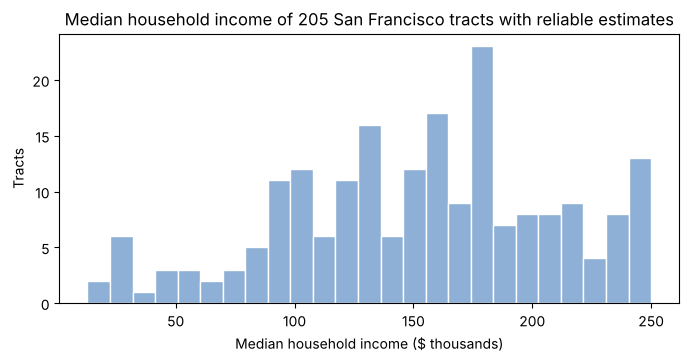

In [30]:
fig, ax = plt.subplots(figsize=(8, 3.5))
reliable = acs.loc[acs["income_reliable"], "income"]
ax.hist(reliable / 1000, bins=25, color="#8fb0d6", edgecolor="white")
ax.set_xlabel("Median household income ($ thousands)")
ax.set_ylabel("Tracts")
ax.set_title(f"Median household income of {len(reliable)} San Francisco tracts with reliable estimates")
plt.show()

In [31]:
acs[["pop", "income", "income_cv"]].describe()

,pop,income,income_cv
count,244.000000,234.000000,224.000000
mean,3402.602459,146049.675214,0.183134
std,1361.064856,58465.039697,0.094992
min,0.000000,12908.000000,0.017471
25%,2495.250000,105023.250000,0.120321
50%,3461.500000,150522.000000,0.161753
75%,4201.250000,183356.250000,0.224635
max,8602.000000,250001.000000,0.543749


## 5. Spatial join check

`spatial_join()` puts each request in the tract polygon it falls in (`gpd.sjoin`, both layers in EPSG:2227).

In [32]:
pd.read_csv(config.LOGS / "spatial_join_log.csv")

,status,requests
0,within,2434029
1,unmatched,899


In [33]:
tracts = load_data.load_sf_tracts()
print("CRS:", tracts.crs.name)
print(len(tracts), "tract polygons |", f"{tracts['request_count'].sum():,}", "requests assigned")
tracts.head()

CRS: NAD83 / California zone 3 (ftUS)
242 tract polygons | 2,434,029 requests assigned


,GEOID,geometry,request_count
0,06075010101,"POLYGON ((6012622.882 2121528.104, 6012271.612...",8726
1,06075010102,"POLYGON ((6009432.631 2120843.205, 6009064.921...",4533
2,06075010201,"POLYGON ((6007528.719 2120580.61, 6007551.601 ...",4755
3,06075010202,"POLYGON ((6007258.49 2122522.965, 6007262.048 ...",7246
4,06075010300,"POLYGON ((6007909.028 2121329.259, 6007926.823...",8197


### 5.1 Tracts in the ACS table but not in the boundary file
The ACS table has 244 San Francisco tracts but the boundary file has 242. The missing ones are water-only tracts,
which have no land for requests to fall in.

In [34]:
not_in_map = acs.loc[~acs["GEOID"].isin(tracts["GEOID"]), ["GEOID", "NAME", "pop", "income"]]
not_in_map

,GEOID,NAME,pop,income
242,06075990100,"Census Tract 9901, San Francisco County, Calif...",0,NaN
243,06075990200,"Census Tract 9902, San Francisco County, Calif...",0,NaN


### 5.2 Requests per tract
A few tracts (downtown, the Mission, the Tenderloin) have far more requests than the rest, so the map uses quantile classes.

In [35]:
tracts["request_count"].describe()

count      242.000000
mean     10057.971074
std       7757.067869
min          0.000000
25%       4887.750000
50%       7928.500000
75%      12129.250000
max      46041.000000
Name: request_count, dtype: float64

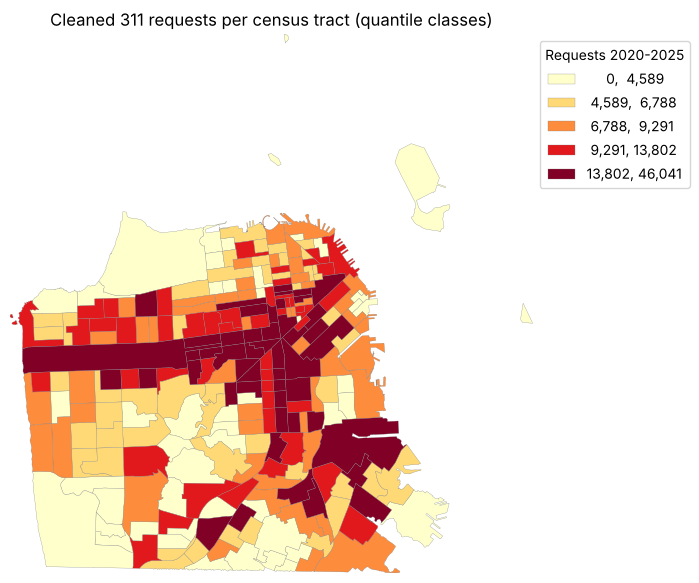

In [36]:
fig, ax = plt.subplots(figsize=(8, 7))
tracts.plot(column="request_count", scheme="quantiles", k=5, cmap="YlOrRd", edgecolor="grey",
            linewidth=0.2, legend=True, ax=ax,
            legend_kwds={"title": "Requests 2020-2025", "fmt": "{:,.0f}",
                         "loc": "upper left", "bbox_to_anchor": (1.0, 1.0)})
# zoom to the city (the Farallon Islands tract is 30 miles offshore)
xmin, ymin, xmax, ymax = tracts.loc[tracts["GEOID"] != "06075980401"].total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()
ax.set_title("Cleaned 311 requests per census tract (quantile classes)")
plt.show()

### 5.3 Requests the join could not place
These 899 requests (0.04%) are inside the San Francisco bounding box but not inside any tract polygon, for example just past the southern city line or on piers along the waterfront. They are left out of the tract counts.

In [37]:
unassigned = pd.read_parquet(config.REQUESTS_UNASSIGNED)
print(len(unassigned), "unassigned requests")
unassigned[["service_request_id", "request_type", "lat", "lon", "spatial_join_status"]].head()

899 unassigned requests


,service_request_id,request_type,lat,lon,spatial_join_status
0,11884419,Street and Sidewalk Cleaning,37.709251,-122.423355,unmatched
1,11884527,Encampments,37.775284,-122.392546,unmatched
2,11885793,Street and Sidewalk Cleaning,37.708225,-122.440536,unmatched
3,11888025,Encampments,37.808414,-122.416679,unmatched
4,11895412,Street and Sidewalk Cleaning,37.789698,-122.388119,unmatched


## 6. Analysis: requests per resident by income group

Functions from `src/analysis/compute_metrics.py`.

### 6.1 Income quartiles
We use tracts in the boundary file with a reliable income estimate and at least 500 residents,
and split them into four equal groups by income.

In [38]:
groups = compute_metrics.income_quartiles(acs, set(tracts["GEOID"]))
print(len(groups), "tracts used")
groups.groupby("income_group", observed=True)["income"].agg(["size", "min", "median", "max"])

203 tracts used


,size,min,median,max
income_group,,,,
Q1 (lowest),51,18217.0,89531.0,113920.0
Q2,51,115125.0,135658.0,156156.0
Q3,50,156713.0,176125.0,189875.0
Q4 (highest),51,190625.0,219750.0,250001.0


### 6.2 Requests per resident per year, for each tract
Rate = requests ÷ residents ÷ 6 years. Raw counts would mostly show which tracts have more people.

In [39]:
assigned = requests.loc[requests["GEOID"].notna(), ["GEOID", "request_type", "year"]].copy()
assigned["GEOID"] = assigned["GEOID"].astype(str)
tract_rates = compute_metrics.rate_by_tract(assigned, groups)
tract_rates.sort_values("rate", ascending=False).head(10)

,GEOID,income,pop,income_group,requests,rate
125,06075022903,189875.0,2798,Q3,31474,1.874792
20,06075011700,51464.0,1914,Q1 (lowest),21420,1.865204
105,06075020801,133953.0,3767,Q2,41160,1.821078
24,06075012001,80300.0,1746,Q1 (lowest),19011,1.814719
76,06075016602,223877.0,1912,Q4 (highest),20128,1.754533
71,06075016200,102035.0,3209,Q1 (lowest),33629,1.746598
107,06075020900,96250.0,3746,Q1 (lowest),37583,1.672139
75,06075016601,134211.0,2836,Q2,25739,1.512635
28,06075012203,23440.0,1524,Q1 (lowest),11788,1.289151
17,06075011102,104966.0,2207,Q1 (lowest),16956,1.280471


The rates are very skewed (a few tracts are far above the rest), so the charts compare the **median** tract in each group, not the mean.

In [40]:
tract_rates.groupby("income_group", observed=True)["rate"].agg(["mean", "median", "min", "max"]).round(2)

,mean,median,min,max
income_group,,,,
Q1 (lowest),0.61,0.46,0.02,1.87
Q2,0.51,0.40,0.18,1.82
Q3,0.47,0.41,0.11,1.87
Q4 (highest),0.38,0.29,0.05,1.75


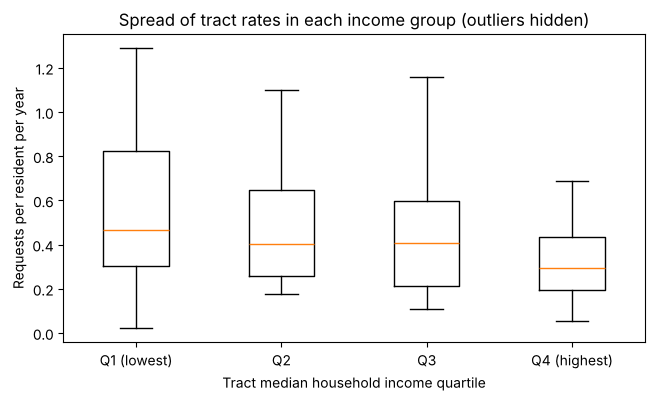

In [41]:
fig, ax = plt.subplots(figsize=(7.5, 4))
data = [tract_rates.loc[tract_rates["income_group"] == q, "rate"] for q in config.QUARTILES]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, 5), config.QUARTILES)
ax.set_xlabel("Tract median household income quartile")
ax.set_ylabel("Requests per resident per year")
ax.set_title("Spread of tract rates in each income group (outliers hidden)")
plt.show()

### 6.3 The three midterm charts
Chart 1 shows the number of requests of each type; chart 2 shows response time (median days from request to closed); chart 3 shows the total number of requests per year in each income group.
Made by `python -m src.main` (`src/visualization/plot_results.py`) and saved in `visualizations/`.

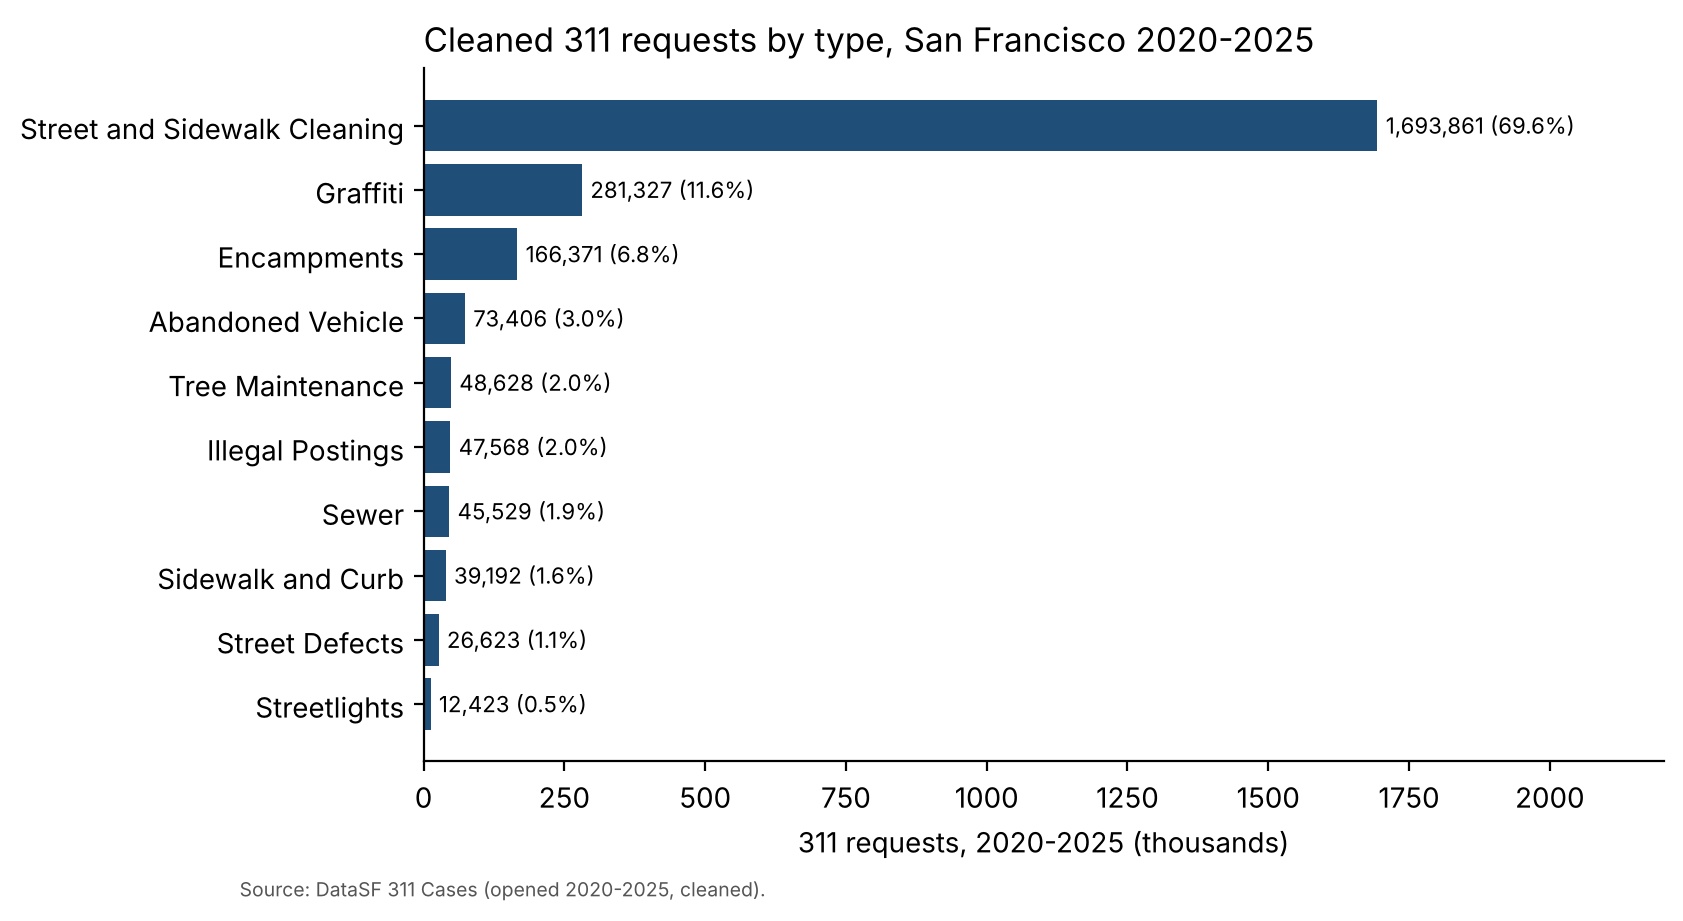

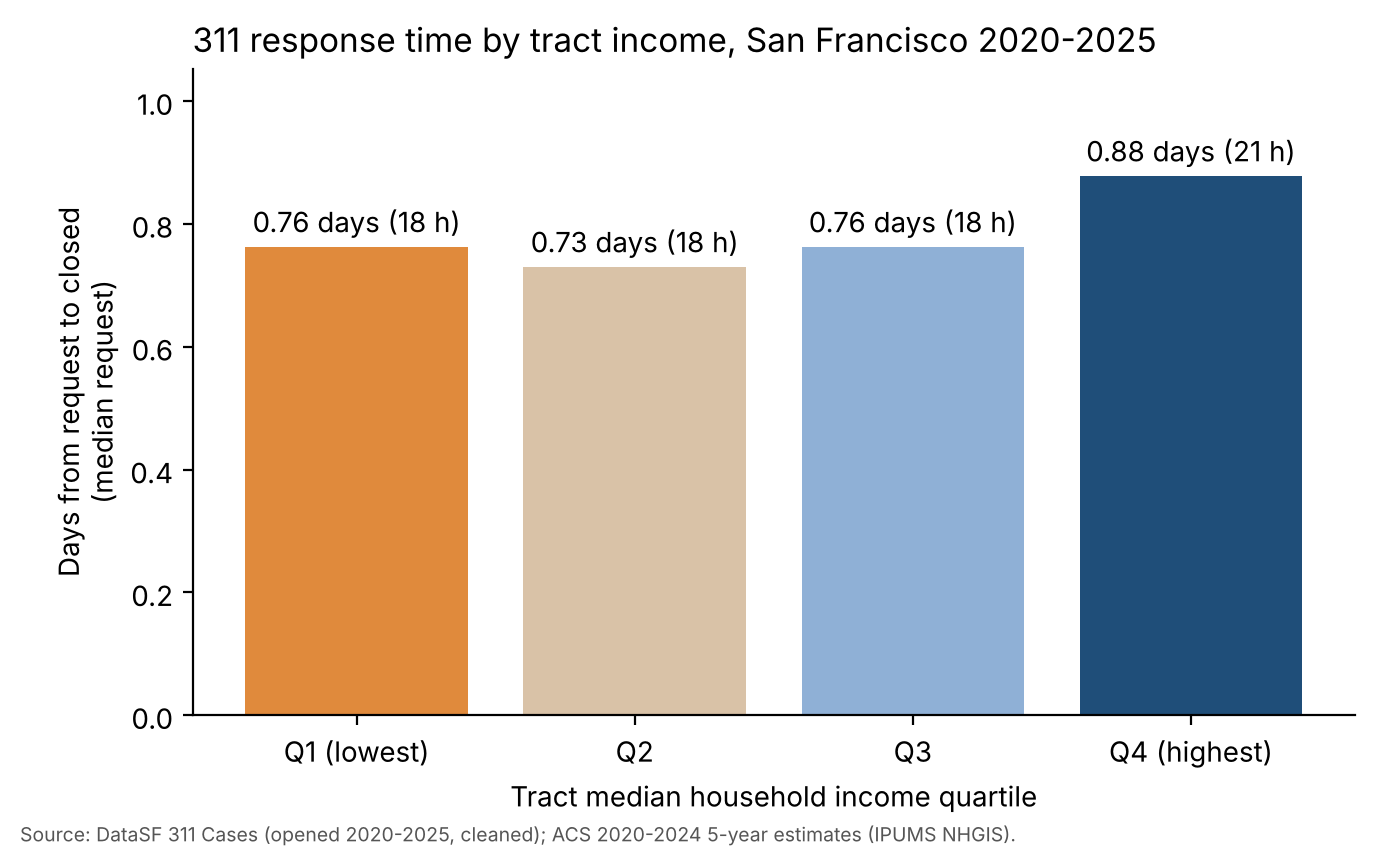

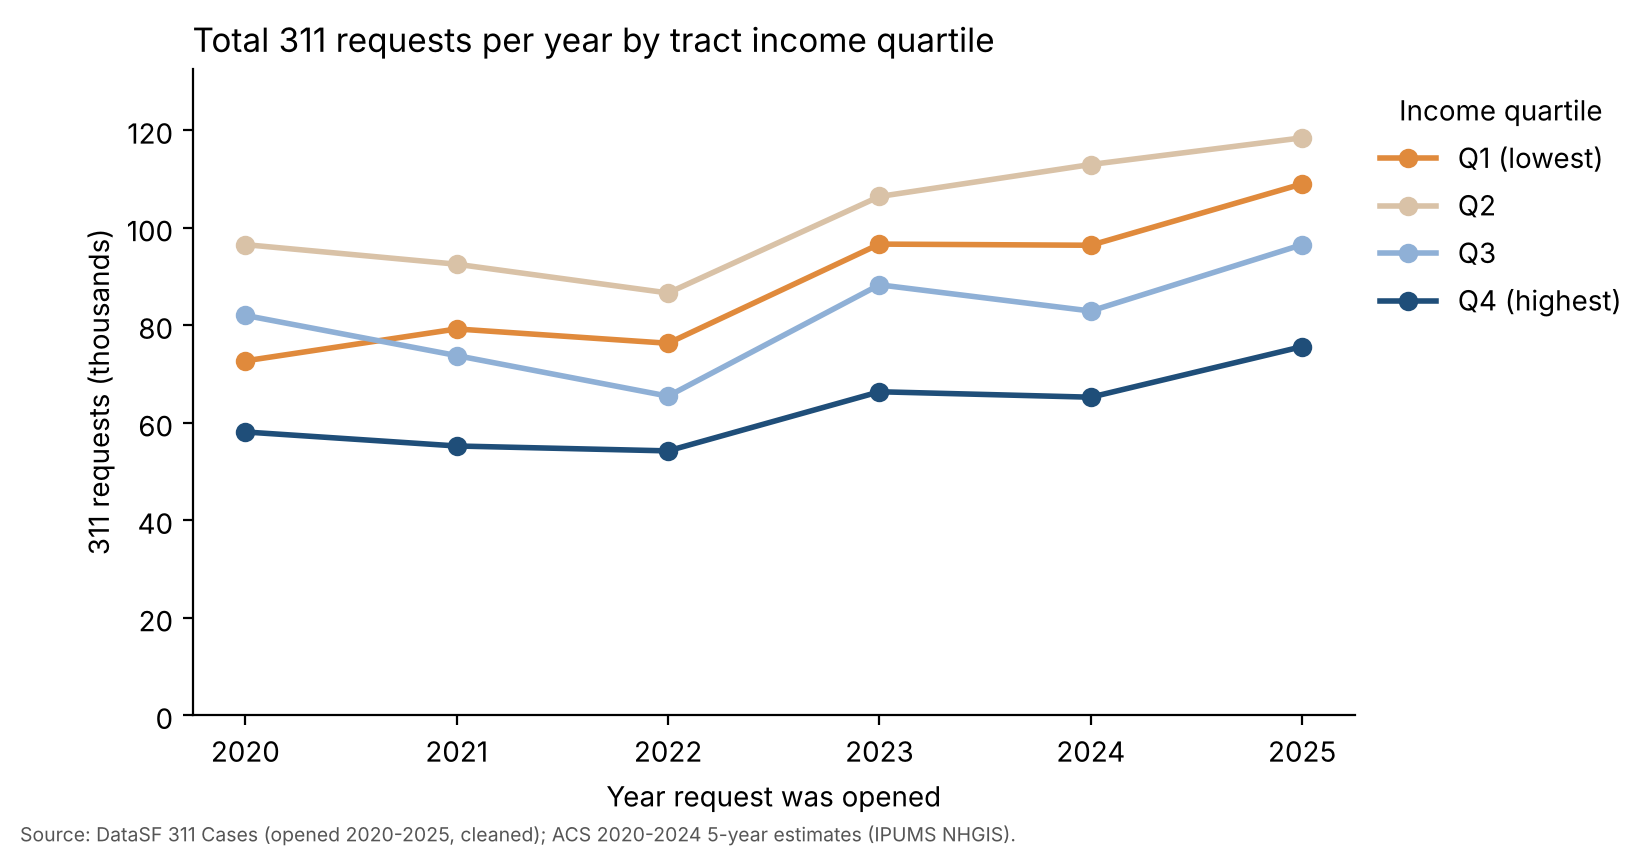

In [42]:
from IPython.display import Image, Markdown, display

for name in ["chart1_requests_by_type.png", "chart2_response_time_by_income.png", "chart3_requests_by_year.png"]:
    display(Image(filename=config.VISUALIZATIONS / name, width=700))

In [43]:
display(Markdown((config.VISUALIZATIONS / "chart_captions.md").read_text()))

# Chart captions

**chart1_requests_by_type.png**: Street and Sidewalk Cleaning makes up 70% of the 2,434,928 cleaned requests from 2020 to 2025, followed by Graffiti (12%).

**chart2_response_time_by_income.png**: The median request in the lowest-income tracts was closed in 18 hours, compared with 21 hours in the highest-income tracts (means are much longer, 7.2 and 11.1 days, because a few requests stay open for months).

**chart3_requests_by_year.png**: Total requests 2020-2025 by income quartile: Q1 (lowest) 530,251, Q2 613,455, Q3 488,972, Q4 (highest) 374,780. Requests in the lowest-income quartile grew from 72,692 in 2020 to 108,983 in 2025.


## Summary of what we found

- 4,374,679 raw requests → 2,434,928 after cleaning; most removals are out-of-scope types and requests closed as duplicates.
- The June 2024 renaming and the closure notes would have distorted the counts without `category_map.csv` and `status_rules.csv`.
- Phone requests often lack coordinates, so they are under-represented.
- 205 of 244 tracts have a reliable income estimate; 203 of them have 500+ residents and are used in the analysis.
- The median lowest-income tract files about 1.6 times as many requests per resident as the median highest-income tract,
  but the gap depends on the type of problem and has grown since 2020.